# Faz 01 — EDA (Exploratory Data Analysis)

**Amaç:** Model kurmadan önce veriyi anlamak. Her bölümde bir soru soruyoruz ve cevabı veriden alıyoruz.

Faz 00 notları: `notes/faz00_bilgi.md` · Bu fazın özeti: `notes/faz01_eda.md`

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_auc_score

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

RAW = Path("../data/raw")
train = pd.read_csv(RAW / "train.csv")
test = pd.read_csv(RAW / "test.csv")

TARGET = "satisfaction"
y = train[TARGET].astype(int)          # True/False → 1/0
BASE_RATE = y.mean()                    # genel memnuniyet oranı

SERVICE = [                             # 13 hizmet puanı (0–5, ordinal)
    "Inflight wifi service", "Departure/Arrival time convenient", "Ease of Online booking",
    "Gate location", "Food and drink", "Online boarding", "Seat comfort",
    "Inflight entertainment", "On-board service", "Leg room service",
    "Baggage handling", "Checkin service", "Cleanliness",
]
CATEGORICAL = ["Gender", "Customer Type", "Type of Travel", "Class"]
NUMERIC = ["Age", "Flight Distance", "Departure Delay in Minutes", "Arrival Delay in Minutes"]

print(train.shape, test.shape, f"base rate = {BASE_RATE:.3f}")

(699635, 23) (299844, 22) base rate = 0.444


## 1. Target dağılımı
**Soru:** Sınıflar dengeli mi? Dengesizse `class_weight`, resampling gibi tekniklere ihtiyaç olur.

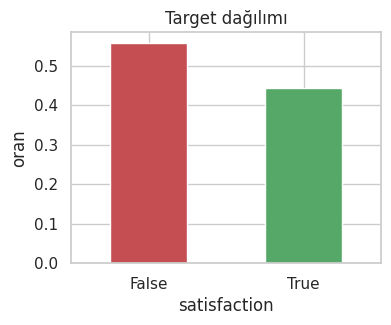

In [2]:
ax = train[TARGET].value_counts(normalize=True).plot.bar(color=["#c44e52", "#55a868"], figsize=(4, 3))
ax.set_title("Target dağılımı"); ax.set_ylabel("oran"); plt.xticks(rotation=0); plt.show()

→ %56 / %44, **neredeyse dengeli**. Özel bir imbalance tekniğine gerek yok. Ayrıca metric ROC-AUC olduğu için dengesizlik zaten sıralamayı bozmaz.

## 2. Hizmet puanları — hangisi en etkili?
**Yöntem:** Her feature'ı tek başına bir "model" gibi kullanıp ROC-AUC hesaplıyoruz (**single-feature AUC**).
- 0.5 → bilgi yok · 1.0 → tek başına mükemmel ayırıyor
- AUC < 0.5 → ters yönde ilişki var (puan arttıkça memnuniyet azalıyor)

Neden correlation değil de AUC? Metric'imiz AUC; ayrıca AUC sadece sıralamaya bakar, ilişkinin doğrusal olmasını beklemez.

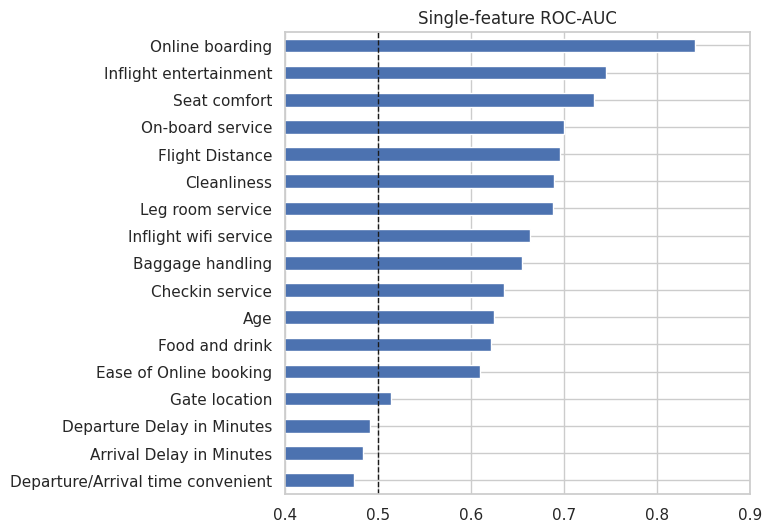

Online boarding                      0.840
Inflight entertainment               0.745
Seat comfort                         0.732
On-board service                     0.699
Flight Distance                      0.696
Cleanliness                          0.689
Leg room service                     0.688
Inflight wifi service                0.663
Baggage handling                     0.655
Checkin service                      0.636
Age                                  0.624
Food and drink                       0.621
Ease of Online booking               0.609
Gate location                        0.514
Departure Delay in Minutes           0.491
Arrival Delay in Minutes             0.484
Departure/Arrival time convenient    0.473
dtype: float64

In [3]:
def single_auc(col):
    ok = train[col].notna()                 # Arrival Delay'de NaN var, AUC NaN kabul etmez
    return roc_auc_score(y[ok], train.loc[ok, col])

auc = pd.Series({c: single_auc(c) for c in SERVICE + NUMERIC}).sort_values()
ax = auc.plot.barh(figsize=(6, 6), color="#4c72b0")
ax.axvline(0.5, color="k", ls="--", lw=1); ax.set_xlim(0.4, 0.9)
ax.set_title("Single-feature ROC-AUC"); plt.show()
auc.sort_values(ascending=False).round(3)

### Her puan değerinde memnuniyet oranı
Renk = o puanı veren yolcuların yüzde kaçı memnun. Genel oran ~0.44.

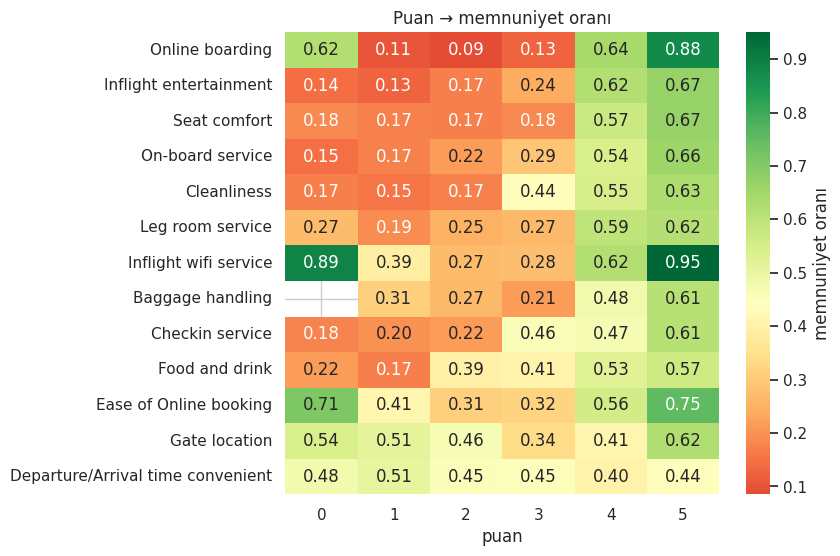

In [4]:
rate = pd.DataFrame({c: train.groupby(c)[TARGET].mean() for c in SERVICE}).T
rate = rate.loc[auc[SERVICE].sort_values(ascending=False).index]
plt.figure(figsize=(7, 6))
sns.heatmap(rate, annot=True, fmt=".2f", cmap="RdYlGn", center=BASE_RATE, cbar_kws={"label": "memnuniyet oranı"})
plt.xlabel("puan"); plt.title("Puan → memnuniyet oranı"); plt.show()

**Gözlemler**
- **Online boarding** açık ara en güçlü (AUC ~0.84). 3→4 geçişinde oran %13'ten %64'e sıçrıyor → ilişki doğrusal değil, bir **eşik** var.
- Çoğu puanda desen aynı: 1–3 kötü, 4–5 iyi. Yani model için "4 ve üstü mü?" bilgisi çok değerli.
- **Gate location** ve **Departure/Arrival time convenient** neredeyse bilgisiz (AUC ~0.5).
- Baggage handling'de hiç 0 yok.

## 3. 0 puanı gerçekten "N/A" mı?
Faz 00'daki hipotez: *0 = değerlendirilmedi, bu yüzden etkisiz olmalı.* Yukarıdaki heatmap'te **wifi=0 → %89 memnun**, Ease of Online booking=0 → %71 memnun. Yani 0 nötr değil.
**Soru:** 0 verenler kim?

In [5]:
zero_cols = ["Inflight wifi service", "Ease of Online booking", "Online boarding"]
summary = pd.DataFrame({
    c: {"0 sayısı": (train[c] == 0).sum(),
        "0 verenlerde memnuniyet": train.loc[train[c] == 0, TARGET].mean(),
        "diğerlerinde memnuniyet": train.loc[train[c] != 0, TARGET].mean()}
    for c in zero_cols
}).T
display(summary.round(3))

wifi0 = train["Inflight wifi service"] == 0
print("wifi=0 olanların Ease of Online booking'i de 0 olma oranı:",
      round((train.loc[wifi0, "Ease of Online booking"] == 0).mean(), 2))
print("\nwifi=0 → Type of Travel:", train.loc[wifi0, "Type of Travel"].value_counts(normalize=True).round(2).to_dict())
print("wifi=0 → Class         :", train.loc[wifi0, "Class"].value_counts(normalize=True).round(2).to_dict())

,0 sayısı,0 verenlerde memnuniyet,diğerlerinde memnuniyet
Inflight wifi service,13102.0,0.887,0.435
Ease of Online booking,16073.0,0.708,0.437
Online boarding,9147.0,0.620,0.441


wifi=0 olanların Ease of Online booking'i de 0 olma oranı: 0.82

wifi=0 → Type of Travel: {'Business travel': 0.8, 'Personal Travel': 0.2}
wifi=0 → Class         : {'Business': 0.63, 'Eco': 0.33, 'Eco Plus': 0.04}


→ 0'lar birlikte geliyor (wifi=0 olanların %82'sinde online booking de 0) ve bu yolcuların çoğu **Business travel + Business class**. Yani 0 rastgele bir eksiklik değil, belirli bir **yolcu profilini** gösteriyor.

**Karar:**
- 0'ı NaN yapıp silmiyoruz; güçlü bir sinyal.
- Tree modeller için olduğu gibi bırakıyoruz (0'ı ayrı bir dalda yakalarlar).
- Linear model kullanırsak `is_zero` flag'leri ekleyeceğiz, çünkü linear model 0'ı "en kötü puan" sanar.

## 4. Categorical feature'lar

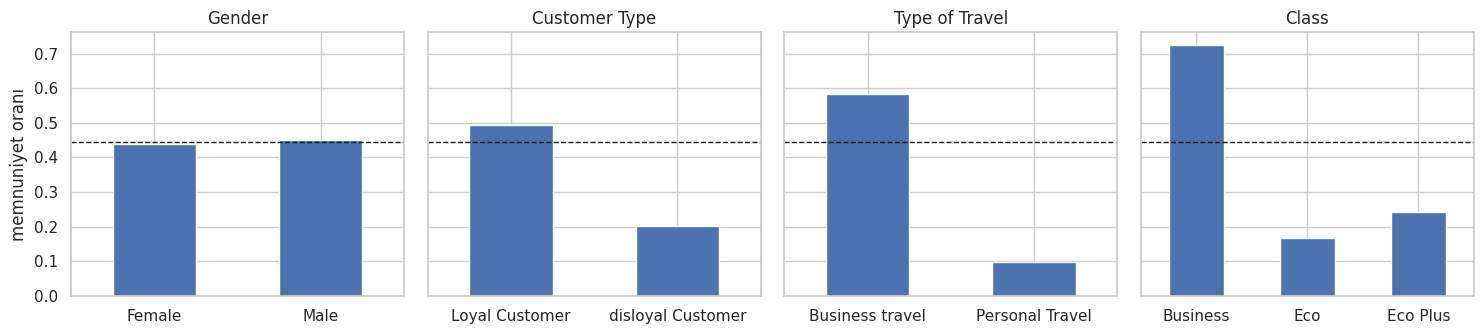

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5), sharey=True)
for ax, c in zip(axes, CATEGORICAL):
    train.groupby(c)[TARGET].mean().plot.bar(ax=ax, color="#4c72b0")
    ax.axhline(BASE_RATE, color="k", ls="--", lw=1); ax.set_title(c); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
axes[0].set_ylabel("memnuniyet oranı"); plt.tight_layout(); plt.show()

### Interaction: Type of Travel × Class
İki feature birlikte, tek tek olduğundan farklı bir şey söylüyor mu?

In [7]:
display(pd.crosstab(train["Type of Travel"], train["Class"], values=train[TARGET], aggfunc="mean").round(3))
display(pd.crosstab(train["Customer Type"], train["Type of Travel"], values=train[TARGET], aggfunc="mean").round(3))

Class,Business,Eco,Eco Plus
Type of Travel,,,
Business travel,0.732,0.260,0.346
Personal Travel,0.112,0.097,0.095


Type of Travel,Business travel,Personal Travel
Customer Type,,
Loyal Customer,0.710,0.097
disloyal Customer,0.201,0.114


**Gözlemler**
- **Personal Travel** yolcuları hangi sınıfta olursa olsun ~%10 memnun. Business class bile onları memnun etmiyor.
- **Business travel + Business class** → %73. Asıl memnun grup bu.
- **Loyal + Business travel** → %71; **disloyal** müşteriler her durumda düşük (~%20).
- **Gender** neredeyse etkisiz (%44 vs %45).

→ Interaction'lar güçlü. Tree modeller bunları kendileri öğrenir, ama Faz 03'te açık bir `travel_class` feature'ı denemeye değer.

## 5. Numeric feature'lar

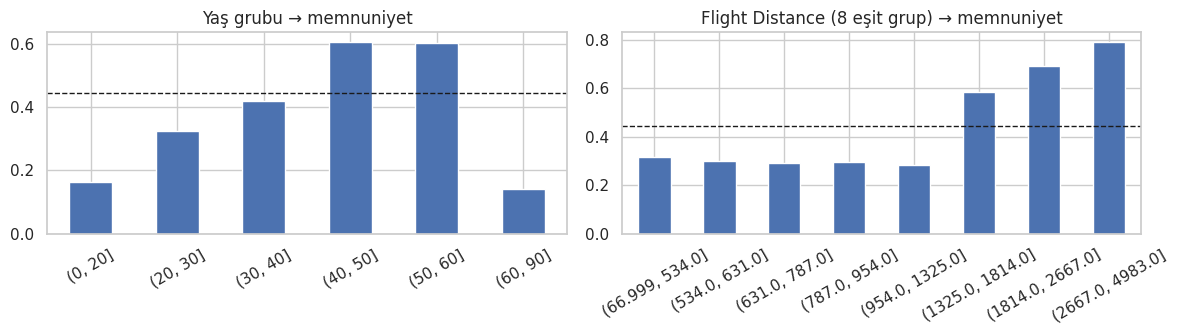

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
train.groupby(pd.cut(train["Age"], [0, 20, 30, 40, 50, 60, 90]), observed=True)[TARGET].mean().plot.bar(ax=axes[0], color="#4c72b0")
axes[0].set_title("Yaş grubu → memnuniyet")
train.groupby(pd.qcut(train["Flight Distance"], 8), observed=True)[TARGET].mean().plot.bar(ax=axes[1], color="#4c72b0")
axes[1].set_title("Flight Distance (8 eşit grup) → memnuniyet")
for ax in axes:
    ax.axhline(BASE_RATE, color="k", ls="--", lw=1); ax.tick_params(axis="x", rotation=30); ax.set_xlabel("")
plt.tight_layout(); plt.show()

- **Age:** ters U şekli. 40–60 yaş ~%60, gençler ve 60+ ~%15. Single-feature AUC bunu iyi göstermez (çünkü monoton değil), ama tree modeller yakalar.
- **Flight Distance:** ~1300 km'de bir **eşik** var. Altında ~%30, üstünde %60–80. Uzun uçuşlar genelde business class.

In [9]:
dep, arr = "Departure Delay in Minutes", "Arrival Delay in Minutes"
print("Gecikme olmayan uçuş oranı:", round((train[dep] == 0).mean(), 3))
print("Departure–Arrival correlation:", round(train[[dep, arr]].corr().iloc[0, 1], 3))
train.groupby(pd.cut(train[arr], [-1, 0, 15, 60, 2000], labels=["0", "1–15", "16–60", "60+"]), observed=True)[TARGET].agg(["mean", "size"]).round(3)

Gecikme olmayan uçuş oranı: 0.908
Departure–Arrival correlation: 0.842


,mean,size
Arrival Delay in Minutes,,
0,0.452,640415
1–15,0.372,40284
16–60,0.306,18334
60+,0.310,310


- Uçuşların **%91'i hiç gecikmemiş** → dağılım çok **skewed**.
- Gecikme arttıkça memnuniyet düşüyor ama etki zayıf (%45 → %31).
- İki gecikme arasında correlation 0.84 → **redundant** (aynı bilgiyi taşıyorlar). Faz 03'te `arr - dep` (yolda kazanılan/kaybedilen zaman) denenebilir.
- `Arrival Delay`'deki 292 NaN: tree modeller NaN'ı kendisi halleder. Gerekirse `Departure Delay` ile doldururuz (yüksek correlation sayesinde mantıklı).

## 6. Hizmet puanları arası correlation
**Soru:** Bazı puanlar aynı şeyi mi ölçüyor?

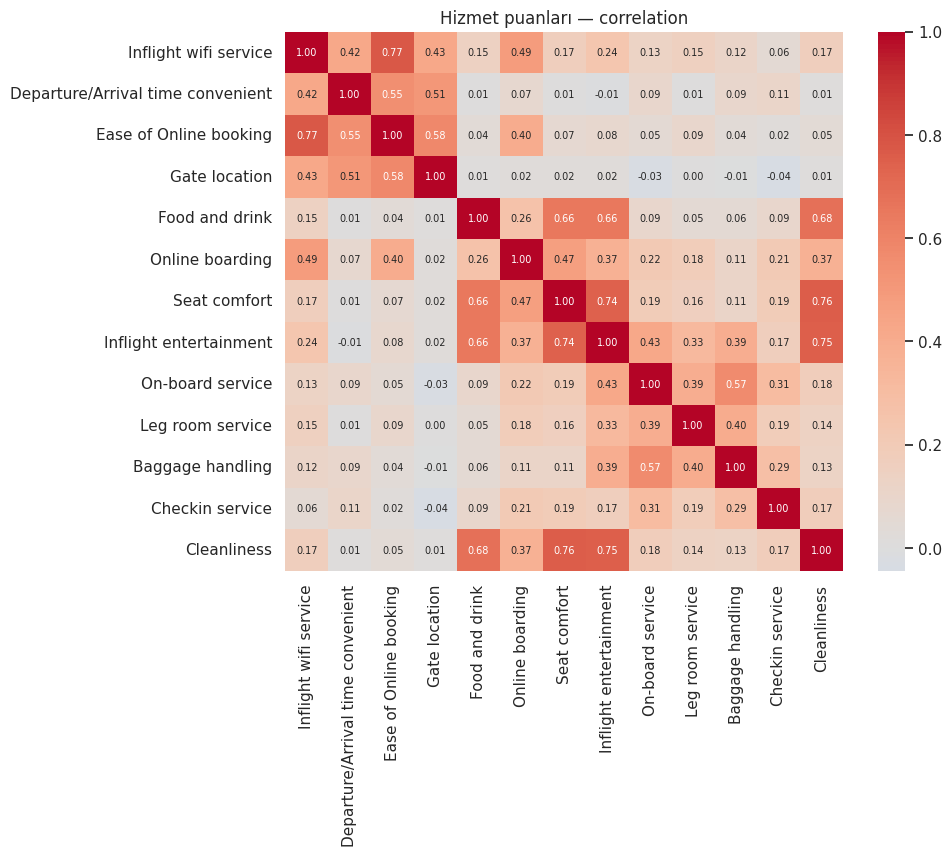

In [10]:
plt.figure(figsize=(9, 7))
sns.heatmap(train[SERVICE].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Hizmet puanları — correlation"); plt.show()

İki küme göze çarpıyor:
- **Uçak içi konfor:** Seat comfort, Inflight entertainment, Cleanliness, Food and drink (0.66–0.76)
- **Online / kapı süreci:** Inflight wifi, Ease of Online booking, Gate location (0.5–0.77)

Tree modeller için multicollinearity büyük sorun değil, ama bu kümelerin ortalaması Faz 03'te yeni feature olabilir.

## 7. Train ve test aynı dağılımdan mı?
Farklıysa, CV skorumuz leaderboard'u yansıtmaz.

In [11]:
cmp = pd.DataFrame({"train": train[NUMERIC + ["Online boarding"]].mean(), "test": test[NUMERIC + ["Online boarding"]].mean()})
display(cmp.round(2))
for c in ["Class", "Type of Travel", "Customer Type"]:
    print(f"{c:15s} train:", train[c].value_counts(normalize=True).round(3).to_dict())
    print(f"{'':15s} test :", test[c].value_counts(normalize=True).round(3).to_dict())
print("\nDuplicate satır (id hariç):", train.drop(columns=["id", TARGET]).duplicated().sum())

,train,test
Age,39.00,38.99
Flight Distance,1353.78,1353.37
Departure Delay in Minutes,1.18,1.16
Arrival Delay in Minutes,1.13,1.12
Online boarding,3.36,3.37


Class           train: {'Business': 0.489, 'Eco': 0.468, 'Eco Plus': 0.043}
                test : {'Business': 0.489, 'Eco': 0.468, 'Eco Plus': 0.043}
Type of Travel  train: {'Business travel': 0.711, 'Personal Travel': 0.289}
                test : {'Business travel': 0.711, 'Personal Travel': 0.289}
Customer Type   train: {'Loyal Customer': 0.825, 'disloyal Customer': 0.175}
                test : {'Loyal Customer': 0.826, 'disloyal Customer': 0.174}



Duplicate satır (id hariç): 0


→ Dağılımlar neredeyse birebir aynı. **Local CV skoruna güvenebiliriz.** Duplicate yok.

## Özet ve sonraki adım
Bulguların kısa özeti `notes/faz01_eda.md` içinde. Faz 02'de bu bulgulara dokunmadan önce basit bir **baseline** kuracağız. Amaç, sonraki her değişikliğin gerçekten işe yarayıp yaramadığını ölçebilmek.